In [3]:
import os
import torch
import torch.nn as nn
from torchvision import transforms
import torch.optim as opt
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from PIL import Image

# checking for GPU

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"using device : {device}")

using device : cuda


In [5]:
data_path = "Train"
demo_path = "demo_test_1"
img_size = 160
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

In [6]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(img_size, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])
test_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])

In [7]:
train_full = ImageFolder(data_path, transform=train_transform)
test_full = ImageFolder(data_path, transform=test_transform)
class_names = train_full.classes
print("classes :", class_names)

classes : ['sp-01', 'sp-02', 'sp-03', 'sp-04', 'sp-05']


In [8]:
train_idx, test_idx = train_test_split(np.arange(len(train_full)), test_size=0.2,
                                       stratify=train_full.targets, random_state=42)
train_data = Subset(train_full, train_idx)
test_data = Subset(test_full, test_idx)
print(f"train images : {len(train_data)} | test images : {len(test_data)}")

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

train images : 2035 | test images : 509


# designing  the neural network

In [9]:
class leaf_model(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2, 2))
        self.conv2 = nn.Sequential(nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2, 2))
        self.conv3 = nn.Sequential(nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2, 2))
        self.conv4 = nn.Sequential(nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1), nn.BatchNorm2d(256), nn.ReLU(), nn.MaxPool2d(2, 2))
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                        nn.Linear(256, 128), nn.ReLU(), nn.Dropout(p=0.5),
                                        nn.Linear(128, len(class_names)))

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.classifier(x)
        return x

In [10]:
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
model = leaf_model().to(device)
optimizer = opt.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = opt.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)
epochs = 40
best_acc = 0

In [11]:
def evaluate(loader):
    model.eval()
    preds, labs = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            preds += outputs.argmax(dim=1).cpu().tolist()
            labs += labels.tolist()
    acc = 100 * np.mean(np.array(preds) == np.array(labs))
    return acc, preds, labs

# training 

In [12]:
epochs = 100

for epoch in range(epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
        output = model(images)
        loss = loss_fn(output, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
        _, predicted = torch.max(output.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        
    scheduler.step()
    
    epoch_loss = total_loss / len(train_loader)
    epoch_acc = 100 * correct / total
    
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_acc:.2f}%")
val_acc, _, _ = evaluate(test_loader)
print(f"epoch{epoch+1}/{epochs}    |  avg loss=  {total_loss / len(train_loader):.4f}  |  val accuracy= {val_acc:.2f}")
if val_acc > best_acc:
  best_acc = val_acc
  torch.save(model.state_dict(), "leaf_dataset_model.pth")

Epoch [10/100] | Loss: 1.2491 | Train Accuracy: 53.51%
Epoch [20/100] | Loss: 1.0454 | Train Accuracy: 67.42%
Epoch [30/100] | Loss: 0.9205 | Train Accuracy: 74.35%
Epoch [40/100] | Loss: 0.8578 | Train Accuracy: 78.08%
Epoch [50/100] | Loss: 0.8341 | Train Accuracy: 80.74%
Epoch [60/100] | Loss: 0.8161 | Train Accuracy: 81.82%
Epoch [70/100] | Loss: 0.8237 | Train Accuracy: 80.64%
Epoch [80/100] | Loss: 0.8034 | Train Accuracy: 82.36%
Epoch [90/100] | Loss: 0.7946 | Train Accuracy: 83.10%
Epoch [100/100] | Loss: 0.7999 | Train Accuracy: 81.87%
epoch100/100    |  avg loss=  0.7999  |  val accuracy= 84.87


# Save the model

In [13]:
model.load_state_dict(torch.load("leaf_dataset_model.pth", map_location=device))
accuracy, all_preds, all_labels = evaluate(test_loader)
print(f"accuracy : {accuracy:.2f}")
print("model saved as  : leaf_dataset_model.pth")

accuracy : 84.87
model saved as  : leaf_dataset_model.pth


# test for a sample image

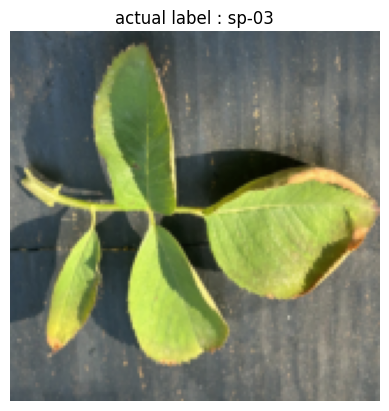

user picked image index 64
actual label sp-03
model prediction  sp-03


In [14]:
index = int(input(f"enter the index number of the leaf (0 to {len(test_data)-1}) "))
image, true_label = test_data[index]
show = image.permute(1, 2, 0).numpy() * np.array(std) + np.array(mean)  
plt.imshow(np.clip(show, 0, 1))
plt.title(f"actual label : {class_names[true_label]}")
plt.axis("off")
plt.show()
image_batch = image.unsqueeze(0).to(device)
with torch.no_grad():
    output = model(image_batch)
    predicted_label = output.argmax(dim=1).item()
print("user picked image index", index)
print("actual label", class_names[true_label])
print("model prediction ", class_names[predicted_label])

# confusion matrix

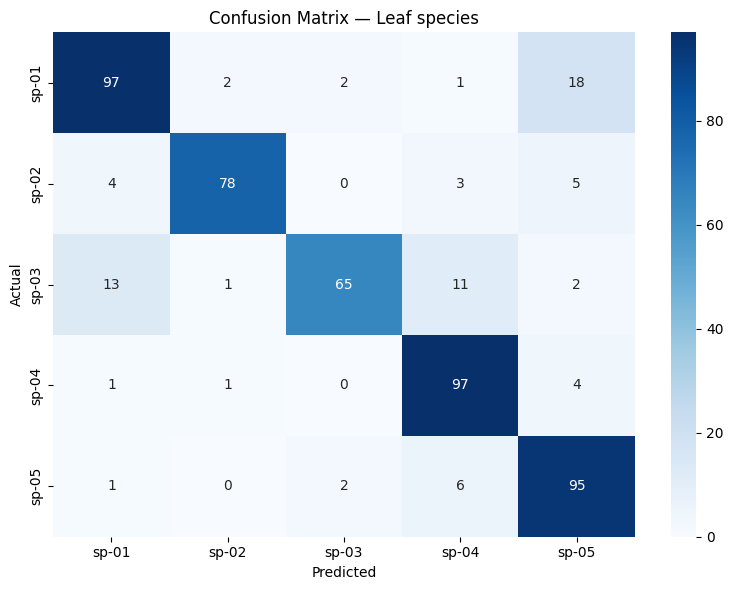

              precision    recall  f1-score   support

       sp-01       0.84      0.81      0.82       120
       sp-02       0.95      0.87      0.91        90
       sp-03       0.94      0.71      0.81        92
       sp-04       0.82      0.94      0.88       103
       sp-05       0.77      0.91      0.83       104

    accuracy                           0.85       509
   macro avg       0.86      0.85      0.85       509
weighted avg       0.86      0.85      0.85       509



In [15]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names, cmap='Blues')
plt.title('Confusion Matrix — Leaf species')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

print(classification_report(all_labels, all_preds, target_names=class_names))

# evaluation

In [16]:
rows = []
model.eval()
for fname in sorted(os.listdir(demo_path)):
    if fname.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")):
        img = Image.open(os.path.join(demo_path, fname)).convert("RGB")
        img = test_transform(img).unsqueeze(0).to(device)
        with torch.no_grad():
            pred = model(img).argmax(dim=1).item()
        rows.append((os.path.splitext(fname)[0], class_names[pred]))

pd.DataFrame(rows, columns=["filename", "species"]).to_csv("demo_predictions.csv", index=False)
print("demo predictions saved as : demo_predictions.csv")

demo predictions saved as : demo_predictions.csv


In [17]:
base = r"C:\Users\sankh\OneDrive\Desktop\makaut_3rd_year"
demos = [("demo_test_1", "demo_test1_true_label"),     
         ("demo_test_2", "demo_test2_true_label")]     

# Loading the model

In [18]:
model.load_state_dict(torch.load("leaf_dataset_model.pth", map_location=device))
model.eval()



leaf_model(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv4): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Batch

In [19]:

def find_path(name, root):
    for dirpath, dirnames, filenames in os.walk(root):
        if name in dirnames or name in filenames:
            return os.path.join(dirpath, name)
    raise FileNotFoundError(f"{name} not found under {root}")



In [20]:

def read_labels(stem, root):
    for dirpath, dirnames, filenames in os.walk(root):
        for f in filenames:
            name, ext = os.path.splitext(f)
            if name == stem and ext.lower() in (".xlsx", ".xls", ".csv"):
                path = os.path.join(dirpath, f)
                print("label file :", path)
                return pd.read_csv(path) if ext.lower() == ".csv" else pd.read_excel(path)
    raise FileNotFoundError(f"{stem}.xlsx/.xls/.csv not found under {root}")


In [21]:


def normalise_label(v):
    """map 3, '3', 'sp-03', 'SP03' ... onto the class names used in training"""
    s = str(v).strip()
    if s in class_names:
        return s
    digits = "".join(ch for ch in s if ch.isdigit())
    if digits and f"sp-{int(digits):02d}" in class_names:
        return f"sp-{int(digits):02d}"
    return s



In [22]:

def predict_folder(folder):
    rows = []
    files = sorted(f for f in os.listdir(folder)
                   if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")))
    for fname in files:
        img = Image.open(os.path.join(folder, fname)).convert("RGB")
        x = test_transform(img).unsqueeze(0).to(device)
        with torch.no_grad():
            
            probs = (model(x).softmax(1) + model(x.flip(3)).softmax(1) + model(x.flip(2)).softmax(1)) / 3
        conf, k = probs.max(1)
        rows.append({"filename": fname, "stem": os.path.splitext(fname)[0],
                     "pred": class_names[k.item()], "confidence": round(conf.item(), 3)})
    return pd.DataFrame(rows)



 # save predictions for this folder 

In [23]:

all_true, all_pred, wrong_rows = [], [], []

for folder_name, label_name in demos:
    print("=" * 60)
    print(folder_name)
    folder_path = find_path(folder_name, base)

    df = predict_folder(folder_path)
    truth = read_labels(label_name, base)
    print("label file columns :", list(truth.columns), "| rows :", len(truth))
    print(truth.head(3).to_string(index=False))

    id_col, lab_col = truth.columns[0], truth.columns[1]      
    truth["stem"] = truth[id_col].astype(str).map(lambda s: os.path.splitext(os.path.basename(s))[0])
    truth["true"] = truth[lab_col].map(normalise_label)

    merged = df.merge(truth[["stem", "true"]], on="stem", how="inner")
    print(f"images predicted : {len(df)} | matched with labels : {len(merged)}")
    if merged.empty:
        print("no names matched - check the id column in the csv")
        continue

    acc = 100 * (merged["pred"] == merged["true"]).mean()
    print(f"accuracy on {folder_name} : {acc:.2f}%")

   
    df[["stem", "pred"]].rename(columns={"stem": "filename", "pred": "species"}) \
        .to_csv(f"pred_{folder_name}.csv", index=False)

    all_true += merged["true"].tolist()
    all_pred += merged["pred"].tolist()
    w = merged[merged["pred"] != merged["true"]].copy()
    w["folder"] = folder_name
    wrong_rows.append(w)


demo_test_1
label file : C:\Users\sankh\OneDrive\Desktop\makaut_3rd_year\demo_test1_true_label.csv
label file columns : ['file', 'label'] | rows : 10
        file label
img_0001.jpg sp-01
img_0002.jpg sp-01
img_0003.jpg sp-02
images predicted : 10 | matched with labels : 10
accuracy on demo_test_1 : 90.00%
demo_test_2
label file : C:\Users\sankh\OneDrive\Desktop\makaut_3rd_year\demo_test2_true_label.csv
label file columns : ['file', 'label'] | rows : 10
        file label
img_0001.jpg sp-02
img_0002.jpg sp-02
img_0003.jpg sp-01
images predicted : 10 | matched with labels : 10
accuracy on demo_test_2 : 100.00%


#  ***combined results***

overall accuracy on both demo folders : 95.00%
              precision    recall  f1-score   support

       sp-01       0.80      1.00      0.89         4
       sp-02       1.00      1.00      1.00         4
       sp-03       1.00      0.75      0.86         4
       sp-04       1.00      1.00      1.00         4
       sp-05       1.00      1.00      1.00         4

    accuracy                           0.95        20
   macro avg       0.96      0.95      0.95        20
weighted avg       0.96      0.95      0.95        20



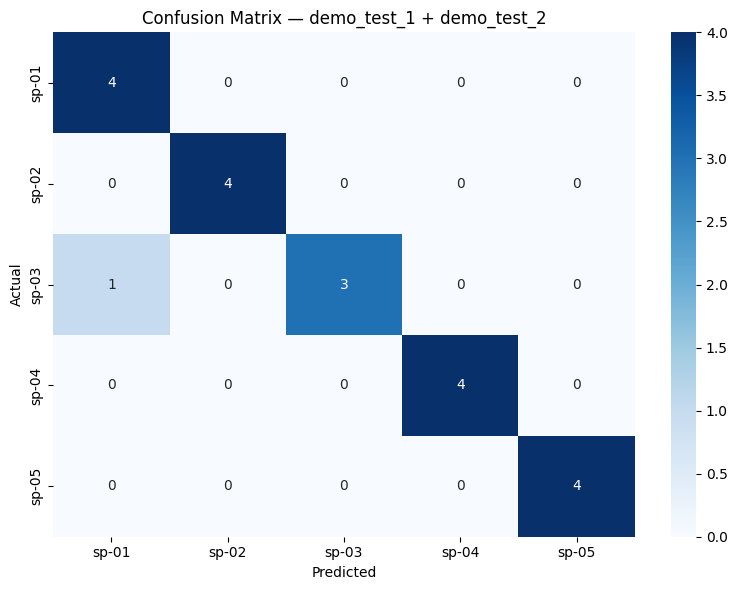

misclassified images :
     folder     filename  true  pred  confidence
demo_test_1 img_0005.jpg sp-03 sp-01       0.394


In [24]:


if all_true:
    print("=" * 60)
    print(f"overall accuracy on both demo folders : {100 * np.mean(np.array(all_true) == np.array(all_pred)):.2f}%")
    print(classification_report(all_true, all_pred, labels=class_names, target_names=class_names, zero_division=0))

    cm = confusion_matrix(all_true, all_pred, labels=class_names)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
    plt.title('Confusion Matrix — demo_test_1 + demo_test_2')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.savefig('demo_confusion_matrix.png')
    plt.show()

    wrong = pd.concat(wrong_rows) if wrong_rows else pd.DataFrame()
    if len(wrong):
        print("misclassified images :")
        print(wrong[["folder", "filename", "true", "pred", "confidence"]].to_string(index=False))
    else:
        print("no misclassified images")
#SSG